In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import sys, glob

# sys.path.append('../')

from spice.spice_bootstrap import *
from spice.plotting import abitreeproblib as tree_prob_plot
from spice.plotting import abitreelib as tree_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


This demo provides instructions to run SPICE on the required input data within a Jupyter notebook. The demo uses input data generated in the accompanying demo within the CNA simulation framework repository.

In [3]:
spice_input_data = pd.read_csv('demo_data/sim/sim_cn_seg_leaf_profiles.tsv.gz', sep='\t')
spice_input_data

,Node,Chr,Pos,Start,End,Allele,CN
0,4,1,1,100000,174100000,A,2
1,4,1,1,100000,174100000,B,0
2,4,1,2,174100000,184600000,A,3
3,4,1,2,174100000,184600000,B,0
4,4,1,3,184600000,186800000,A,3
...,...,...,...,...,...,...,...
1411,7,22,5,1600000,1700000,B,0
1412,7,22,6,1700000,14600000,A,4
1413,7,22,6,1700000,14600000,B,0
1414,7,22,7,14600000,50818468,A,2


### Input to the SPICE

SPICE takes in input multiple parameters:

`leaves_df`: A DataFrame containing copy number profiles and segment information for each leaf (clone). Each row corresponds to a genomic segment with associated copy number data.

`min_seg_size`: The minimum segment size (in base pairs) considered in the ILP model of SPICE. Segments smaller than this threshold undergo phylogenetic reconstruction using the alternative, simpler, evolutionary model (`default=0`).

`max_n_segs`: The maximum number of segments to include in the ILP model. Segments are ranked in decreasing order of size and the top `max_n_segs` are included. The other segments undergo phylogenetic reconstruction using the alternative, simpler, evolutionary model. If None, all segments are used. (default=None).

`keep_consec_segs`: Only used when either of `min_seg_size` or `max_n_segs` are active. Ensures that any segments contiguous with small segments are kept for ILP inference. (`default=False`).

`allele_specific`: If True, inference is performed on allele-specific copy number profiles (major/minor). If False, total copy number is used (`default=True`).

`phase_alleles`: Determines whether alleles should be phased before inference (`default=False`).

`leaf_dependent_phasing`: If False, phasing is performed independently for each leaf. If True, global phasing is used across all leaves (`default=True`).

`max_cn`: The maximum copy number per segment. Copy numbers above this threshold are truncated (`default=8`).

`verbose`: Controls the verbosity of console output. If True, detailed progress and debug messages are printed (`default=True`).

`rs`: Random seed (`default=1`).

`n_threads`: The number of computational threads used for parallel execution (`default=1`).

`time_limit`: The maximum time (in hours) allowed for the inference process to complete (`default=5`).

`boot_distfunc`: The distance function used for Neighbour Joining when inferring the phylogenetic tree topology. Common options include 'bphamm' (breakpoint Hamming distance) (`default='bphamm'`).

`weight_wgd`: Whether to assign additional weight (where the weight is equivalent to the `max_cn` value) to whole genome duplication (WGD) events in the ILP (`default=True`).

`wgd_fract_genome`: The fraction of each allele that must be affected by a WGD event in achild node to keep the inference of WGD from the ILP model (`default=0.5`).

`multiple_solutions`: If True, multiple possible phylogenetic solutions are enumerated by SPICE, otherwise only the optimal tree is returned. (`default=True`)

`solution_pool_size`: The number of alternative ancestral node solutions to enumerate from the ILP model (`default=1000`).

`n_bootstraps`: The number of bootstrap replicates performed inferring phylogenetic tree topologies (`default=1000`).

`fixed_topology`: If tuple of (parent, child) relationships describing the topology is provided, the tree topology is fixed, and only ancestral nodes are inferred (`default=False`)

`topology_prop_limit`: The minimum threshold on the proportion of solutions for each topology that must be present to keep in the solution pool (`default=0.025`).

`debug`: Outputs more detailed information on the model for debugging only (`default=False`).

`rank_multiple_trees`: If True, multiple inferred trees are ranked according to their probability (`default=True`).

`output_type`: Specifies the output mode. Options include 'return' (returns results to the session), 'save' (writes results to disk) or 'both' (`default='save'`).

`output_dir`: Directory to which inference outputs, logs, and plots are saved. If None, results are not written to current directory (`default=None`).

In [4]:
spice_res = run_spice_bootstrap(spice_input_data, 
                        min_seg_size=5e4, 
                        max_n_segs=None,
                        keep_consec_segs=False,
                        allele_specific=True,
                        phase_alleles=False,
                        leaf_dependent_phasing=True,
                        max_cn=8,
                        focal_max_cn=None,
                        verbose=True,
                        rs=1,
                        n_threads=1,
                        time_limit=5,
                        weight_wgd=True,
                        wgd_fract_genome=0.5,
                        multiple_solutions=True,
                        solution_pool_size=250, # This is a reduced solution pool size compared to the default value (1000) for the purposes of the demo
                        max_cutoff=2,
                        n_bootstraps=1000,
                        fixed_topology=False,
                        topology_prop_limit=0.025,
                        topology_topn=10,
                        initnodes=None,
                        debug=False,
                        rm_small_segs=False,
                        rank_multiple_trees=True,
                        output_type='return',
                        output_dir=None)

SPICE 2026-07-06 11:53:13,184 | INFO | spice_bootstrap.py >>> Processing input data
SPICE 2026-07-06 11:53:13,191 | TRACE | spice_io.py >>> Collapsing CN bins to segments.
SPICE 2026-07-06 11:53:13,574 | TRACE | spice_io.py >>> Selecting segments above a min_seg_size of 50.0kb.
SPICE 2026-07-06 11:53:13,578 | INFO | spice_io.py >>> Total number of segments before filtering: 354
SPICE 2026-07-06 11:53:13,608 | INFO | spice_io.py >>> Total number of segments after filtering: 354
SPICE 2026-07-06 11:53:13,886 | TRACE | spice_io.py >>> Clipping interval model CN profiles to maximum value of 8. Previous maximum value was 7. 0.00% of input CN values were above the threshold.
SPICE 2026-07-06 11:53:13,891 | TRACE | spice_io.py >>> Clipping small segment model CN profiles to maximum value of 8. Previous maximum value was 7. 0.00% of input CN values were above the threshold.
SPICE 2026-07-06 11:53:14,375 | INFO | spice_io.py >>> Processed input CN profiles. 4 leaves with 209 final segments
SPIC

Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 2
Set parameter TimeLimit to value 1479
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (linux64 - "Rocky Linux 8.7 (Green Obsidian)")

CPU model: AMD EPYC 7763 64-Core Processor, instruction set [SSE2|AVX|AVX2]
Thread count: 128 physical cores, 256 logical processors, using up to 1 threads

Optimize a model with 61027 rows, 32149 columns and 145902 nonzeros
Model fingerprint: 0xdd121104
Variable types: 0 continuous, 32149 integer (10226 binary)
Coefficient statistics:
  Matrix range     [1e+00, 8e+00]
  Objective range  [1e-05, 8e+00]
  Bounds range     [1e+00, 8e+00]
  RHS range        [1e+00, 8e+00]

User MIP start produced solution with objective 621.981 (0.07s)
Loaded user MIP start with objective 621.981

Presolve removed 32906 rows and 14616 columns
Presolve time: 2.33s
Presolved: 28121 rows, 17533 columns, 70240 nonzeros
Variable types: 0 continuous, 17533 integer (4703 binary)
Root 

SPICE 2026-07-06 12:25:53,992 | TRACE | optimal_tree_ilp.py >>> Processing ILP output
SPICE 2026-07-06 12:25:55,221 | WARNING | spice_bootstrap.py >>> SPICE ILP did not complete to optimality for topology 1 of 10: status = time_limit
SPICE 2026-07-06 12:25:55,223 | WARNING | spice_bootstrap.py >>> Optimal solution not reached for topology 1 of 10: Gap of 1.41 found - consider increasing time limit
SPICE 2026-07-06 12:25:55,226 | TRACE | multi_solution_ilp.py >>> Checking multiple solutions input
SPICE 2026-07-06 12:25:55,230 | TRACE | multi_solution_ilp.py >>> Input valid
SPICE 2026-07-06 12:25:55,231 | TRACE | multi_solution_ilp.py >>> Defining ILP
SPICE 2026-07-06 12:25:55,378 | TRACE | multi_solution_ilp.py >>> Adding model variables
SPICE 2026-07-06 12:26:04,726 | TRACE | multi_solution_ilp.py >>> Adding model constraints
SPICE 2026-07-06 12:26:27,015 | TRACE | multi_solution_ilp.py >>> Adding model objective
SPICE 2026-07-06 12:26:27,178 | TRACE | multi_solution_ilp.py >>> ILP def

      123.04 seconds required for presolve
Set parameter Threads to value 1
Set parameter Seed to value 1
Set parameter MIPFocus to value 1
Set parameter Cutoff to value 2.8598177916146938e+02
Set parameter PoolSearchMode to value 2
Set parameter PoolSolutions to value 112
Set parameter TimeLimit to value 3451
Gurobi Optimizer version 11.0.2 build v11.0.2rc0 (linux64 - "Rocky Linux 8.7 (Green Obsidian)")

CPU model: AMD EPYC 7763 64-Core Processor, instruction set [SSE2|AVX|AVX2]
Thread count: 128 physical cores, 256 logical processors, using up to 1 threads

Optimize a model with 612607 rows, 82010 columns and 1362497 nonzeros
Model fingerprint: 0x52f5a893
Variable types: 0 continuous, 82010 integer (38079 binary)
Coefficient statistics:
  Matrix range     [1e+00, 8e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 8e+00]
  RHS range        [1e+00, 8e+00]

User MIP start produced solution with objective 148 (0.28s)
Loaded user MIP start with objective 148

Presolve rem

SPICE 2026-07-06 12:35:10,835 | TRACE | multi_solution_ilp.py >>> Processing ILP output


        3.86 seconds required for postsolve
starting process output 2026-07-06 12:35:10.869800


... (73 outputs left out)

process output complete 2026-07-06 13:53:35.619113


SPICE 2026-07-06 13:53:39,457 | INFO | spice_bootstrap.py >>> SPICE ILP complete: total ILP time = 6764.1
SPICE 2026-07-06 13:53:42,549 | INFO | ilp_functions.py >>> No duplicate solutions found
SPICE 2026-07-06 13:53:43,401 | INFO | spice_bootstrap.py >>> Ranking multiple solutions using geometric weighting function
SPICE 2026-07-06 13:53:43,403 | TRACE | solution_probabilities.py >>> Getting unique trees
SPICE 2026-07-06 13:53:43,449 | TRACE | solution_probabilities.py >>> Calculating topology probabilities
SPICE 2026-07-06 13:53:43,547 | TRACE | solution_probabilities.py >>> Calculating copy-number state probabilities


weight func =  geometric


SPICE 2026-07-06 13:54:03,081 | TRACE | solution_probabilities.py >>> Calculating tree rankings
SPICE 2026-07-06 13:54:03,216 | INFO | spice_bootstrap.py >>> Ranking multiple solutions complete
SPICE 2026-07-06 13:54:03,218 | INFO | spice_bootstrap.py >>> Total SPICE run time: 7250.03s
SPICE 2026-07-06 13:54:04,468 | INFO | spice_bootstrap.py >>> Peak memory usage: 1966.24 MB
SPICE 2026-07-06 13:54:04,476 | INFO | spice_bootstrap.py >>> SPICE complete


The following files are output from the simulation framework:

- `total_nodes_multisol`: The output copy number profiles by SPICE for every solution enumerated in the enumerate ILP.

In [5]:
spice_res['total_nodes_multisol']

,tree_id,Solution,Node,Chr,Pos,Start,End,DeletionsA,DeletionsB,GainsA,GainsB,cnA,cnB
0,1,m1,0,1,1,100000,174100000,0.0,0.0,0.0,0.0,1.0,1.0
1,1,m1,0,1,2,174100000,184600000,0.0,0.0,0.0,0.0,1.0,1.0
2,1,m1,0,1,3,184600000,186800000,0.0,0.0,0.0,0.0,1.0,1.0
3,1,m1,0,1,4,186800000,189000000,0.0,0.0,0.0,0.0,1.0,1.0
4,1,m1,0,1,5,189000000,248956422,0.0,0.0,0.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
368155,10,m251,clone_7,22,3,1300000,1400000,0.0,0.0,0.0,0.0,6.0,0.0
368156,10,m251,clone_7,22,4,1400000,1600000,0.0,0.0,0.0,0.0,4.0,0.0
368157,10,m251,clone_7,22,5,1600000,1700000,0.0,0.0,0.0,0.0,4.0,0.0
368158,10,m251,clone_7,22,6,1700000,14600000,0.0,0.0,0.0,0.0,4.0,0.0


- `total_edges_multisol`: The output edges of the phylogeny by SPICE for every solution enumerated in the enumerate ILP.

In [6]:
spice_res['total_edges_multisol']

,Solution,Parent,Child,Events,Deletions,Gains,WGD,Total_cost,Gurobi_cost,tree_id,weight_cost_col,Tree_weight
70,m1,0,1,87,44,43,1,136,144.0,1,136,0.800
71,m1,1,2,4,4,0,0,136,144.0,1,136,0.800
72,m1,1,3,4,1,3,0,136,144.0,1,136,0.800
73,m1,2,clone_4,15,5,10,0,136,144.0,1,136,0.800
74,m1,2,clone_7,8,2,6,0,136,144.0,1,136,0.800
...,...,...,...,...,...,...,...,...,...,...,...,...
1822,m251,1,clone_5,12,6,6,0,138,146.0,10,138,0.032
1823,m251,2,3,6,6,0,0,138,146.0,10,138,0.032
1824,m251,2,clone_6,9,4,5,0,138,146.0,10,138,0.032
1825,m251,3,clone_4,15,5,10,0,138,146.0,10,138,0.032


- `total_nodes_optimal`: The output copy number profiles by SPICE for only the optimal solutions (one for each inferred topology) output by the optimal ILP.

In [7]:
spice_res['total_nodes_optimal']

,tree_id,Solution,Node,Chr,Pos,Start,End,DeletionsA,DeletionsB,GainsA,GainsB,cnA,cnB
158592,1,o1,0,1,1,100000,174100000,0.0,0.0,0.0,0.0,1.0,1.0
158593,1,o1,0,1,2,174100000,184600000,0.0,0.0,0.0,0.0,1.0,1.0
158594,1,o1,0,1,3,184600000,186800000,0.0,0.0,0.0,0.0,1.0,1.0
158595,1,o1,0,1,4,186800000,189000000,0.0,0.0,0.0,0.0,1.0,1.0
158596,1,o1,0,1,5,189000000,248956422,0.0,0.0,0.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369571,10,o10,clone_7,22,3,1300000,1400000,0.0,0.0,0.0,0.0,6.0,0.0
369572,10,o10,clone_7,22,4,1400000,1600000,0.0,0.0,0.0,0.0,4.0,0.0
369573,10,o10,clone_7,22,5,1600000,1700000,0.0,0.0,0.0,0.0,4.0,0.0
369574,10,o10,clone_7,22,6,1700000,14600000,0.0,0.0,0.0,0.0,4.0,0.0


- `total_edges_optimal`: The output edges of the phylogeny by SPICE for only the optimal solutions (one for each inferred topology) output by the optimal ILP.

In [8]:
spice_res['total_edges_optimal']

,Solution,Parent,Child,Events,Deletions,Gains,WGD,Total_cost,Gurobi_cost,tree_id
0,o1,0,1,86,42,44,1,134,142.990890,1
1,o1,1,2,5,5,0,0,134,142.990890,1
2,o1,1,3,3,1,2,0,134,142.990890,1
3,o1,2,clone_4,14,5,9,0,134,142.990890,1
4,o1,2,clone_7,8,3,5,0,134,142.990890,1
...,...,...,...,...,...,...,...,...,...,...
65,o10,1,clone_5,11,5,6,0,136,144.990927,10
66,o10,2,3,6,6,0,0,136,144.990927,10
67,o10,2,clone_6,8,3,5,0,136,144.990927,10
68,o10,3,clone_4,14,4,10,0,136,144.990927,10


- `total_events`: All events in each of the enumerated solutions output by SPICE. This currently includes only events from the ILP, and not those from the alternative, simpler model.

In [9]:
spice_res['total_events']

,tree_id,Solution,Node,Chr,Start,End,startPos,endPos,Allele,Event,nEvents
0,1,m1,1,1,100000,248956422,1,5,1,Deletion,1.0
1,1,m1,1,2,100000,93900000,1,2,1,Deletion,1.0
2,1,m1,1,2,100000,2400000,1,1,0,Gain,1.0
3,1,m1,1,2,126100000,136100000,5,6,1,Deletion,1.0
4,1,m1,1,2,122200000,126300000,4,5,0,Gain,1.0
...,...,...,...,...,...,...,...,...,...,...,...
33367,10,m251,clone_7,9,80800000,98700000,13,13,0,Gain,1.0
33368,10,m251,clone_7,9,99100000,138394717,15,15,0,Gain,1.0
33369,10,m251,clone_7,14,100000,900000,1,1,1,Deletion,2.0
33370,10,m251,clone_7,18,53600000,58300000,12,15,0,Gain,1.0


- `solution_probabilities`: The calculated probabilities of each topology, CN profile, and over solution probability for every solution enumerated by SPICE, along with the ranking of each solution.

In [10]:
spice_res['solution_probabilities']

,tree_id,Solution,Tree_weight,Tree,topology_prob,cn_prob,solution_prob,topology_prob_norm,cn_prob_norm,solution_prob_norm,topology_rank,top>cn_solution_rank,topxcn_solution_rank,topxcn_norm_solution_rank,Total_cost,Gurobi_cost
0,1,m1,0.80000,"((0, 1), (1, 2), (1, 3), (2, clone_4), (2, clo...",-0.027598,-9.296795,-9.324392,0.001458,0.048735,0.050193,1,1,1,1,136,144.0
1,1,m10,0.80000,"((0, 1), (1, 2), (1, 3), (2, clone_4), (2, clo...",-0.027598,-12.157544,-12.185142,0.001458,0.063731,0.065189,1,9,9,9,136,144.0
2,1,m100,0.16000,"((0, 1), (1, 2), (1, 3), (2, clone_4), (2, clo...",-0.027598,-64.021595,-64.049193,0.001458,0.335606,0.337065,1,55,92,55,137,145.0
3,1,m101,0.16000,"((0, 1), (1, 2), (1, 3), (2, clone_4), (2, clo...",-0.027598,-24.983475,-25.011072,0.001458,0.130965,0.132424,1,40,40,40,137,145.0
4,1,m102,0.16000,"((0, 1), (1, 2), (1, 3), (2, clone_4), (2, clo...",-0.027598,-21.030325,-21.057923,0.001458,0.110243,0.111701,1,31,31,31,137,145.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246,8,m247,0.00128,"((0, 1), (1, 2), (1, clone_4), (2, 3), (2, clo...",-17.311306,-54.565011,-71.876317,0.914859,0.286034,1.200893,8,243,95,103,140,148.0
247,9,m248,0.00640,"((0, 1), (1, 2), (1, 3), (2, clone_4), (2, clo...",-12.760184,-68.972080,-81.732264,0.674344,0.361557,1.035901,3,123,96,86,139,147.0
248,9,m249,0.00640,"((0, 1), (1, 2), (1, 3), (2, clone_4), (2, clo...",-12.760184,-73.143039,-85.903223,0.674344,0.383422,1.057765,3,124,98,92,139,147.0
249,9,m250,0.00640,"((0, 1), (1, 2), (1, 3), (2, clone_4), (2, clo...",-12.760184,-68.972080,-81.732264,0.674344,0.361557,1.035901,3,123,96,86,139,147.0


- `chosen_topology_cn_probabilities`: The probability of each inferred ancestral copy number state, calculated only for the top-ranked phylogenetic topology.

In [11]:
spice_res['chosen_topology_cn_probabilities']

,Node,Chr,Pos,Start,End,Allele,CN,CN_probability,tree_id
0,1,10,1,100000,99300000,cnA,2.0,1.0,1
1,1,10,1,100000,99300000,cnB,1.0,1.0,1
2,1,10,2,99300000,104700000,cnA,2.0,1.0,1
3,1,10,2,99300000,104700000,cnB,2.0,1.0,1
4,1,10,3,104700000,105400000,cnA,2.0,1.0,1
...,...,...,...,...,...,...,...,...,...
1107,3,9,7,5800000,6000000,cnB,2.0,1.0,1
1108,3,9,8,6000000,6600000,cnA,2.0,1.0,1
1109,3,9,8,6000000,6600000,cnB,2.0,1.0,1
1110,3,9,9,6600000,7200000,cnA,2.0,1.0,1


- `solve_info`: Details the information for the ILP solving for every topology and both the optimal and enumerate ILP. Includes run time, solve status and number of CNAs.

In [12]:
spice_res['solve_info']

,parameter,value,tree_id
0,optimal_tree_solve_time,1494.002492,1.0
1,optimal_tree_model_status,time_limit,1.0
2,optimal_tree_gap,1.41,1.0
3,optimal_tree_total_cost,142.99089,1.0
4,optimal_tree_solve_time,315.029826,2.0
...,...,...,...
97,multi_solution_total_cost_range,"146.0, ...",10.0
98,n_solutions,1,10.0
99,n_optimal_solutions,1,10.0
100,total_run_time,7250.034626,NaN


- `mapping`: A mapping of the input copy number segments to those input to the ILP model (including altered segment names as a result of the filtering and collapsing of segments).

In [13]:
spice_res['mapping']

,Chr,Allele,Start,End,origPos,mergePos,filteredPos,finalPos
0,1,0,100000,174100000,1,1,1,1
1,1,0,174100000,184600000,2,2,2,2
2,1,0,184600000,186800000,3,3,3,3
3,1,0,186800000,189000000,4,4,4,4
4,1,0,189000000,248956422,5,5,5,5
...,...,...,...,...,...,...,...,...
349,22,1,1300000,1400000,3,3,3,1
350,22,1,1400000,1600000,4,4,4,1
351,22,1,1600000,1700000,5,5,5,1
352,22,1,1700000,14600000,6,6,6,1


The output of SPICE can also be visualised using the plotting functions of SPICE. Specifically, it is possible to visualise the CN probabilities for the top-ranked topology, or the copy number profiles of individual solutions.

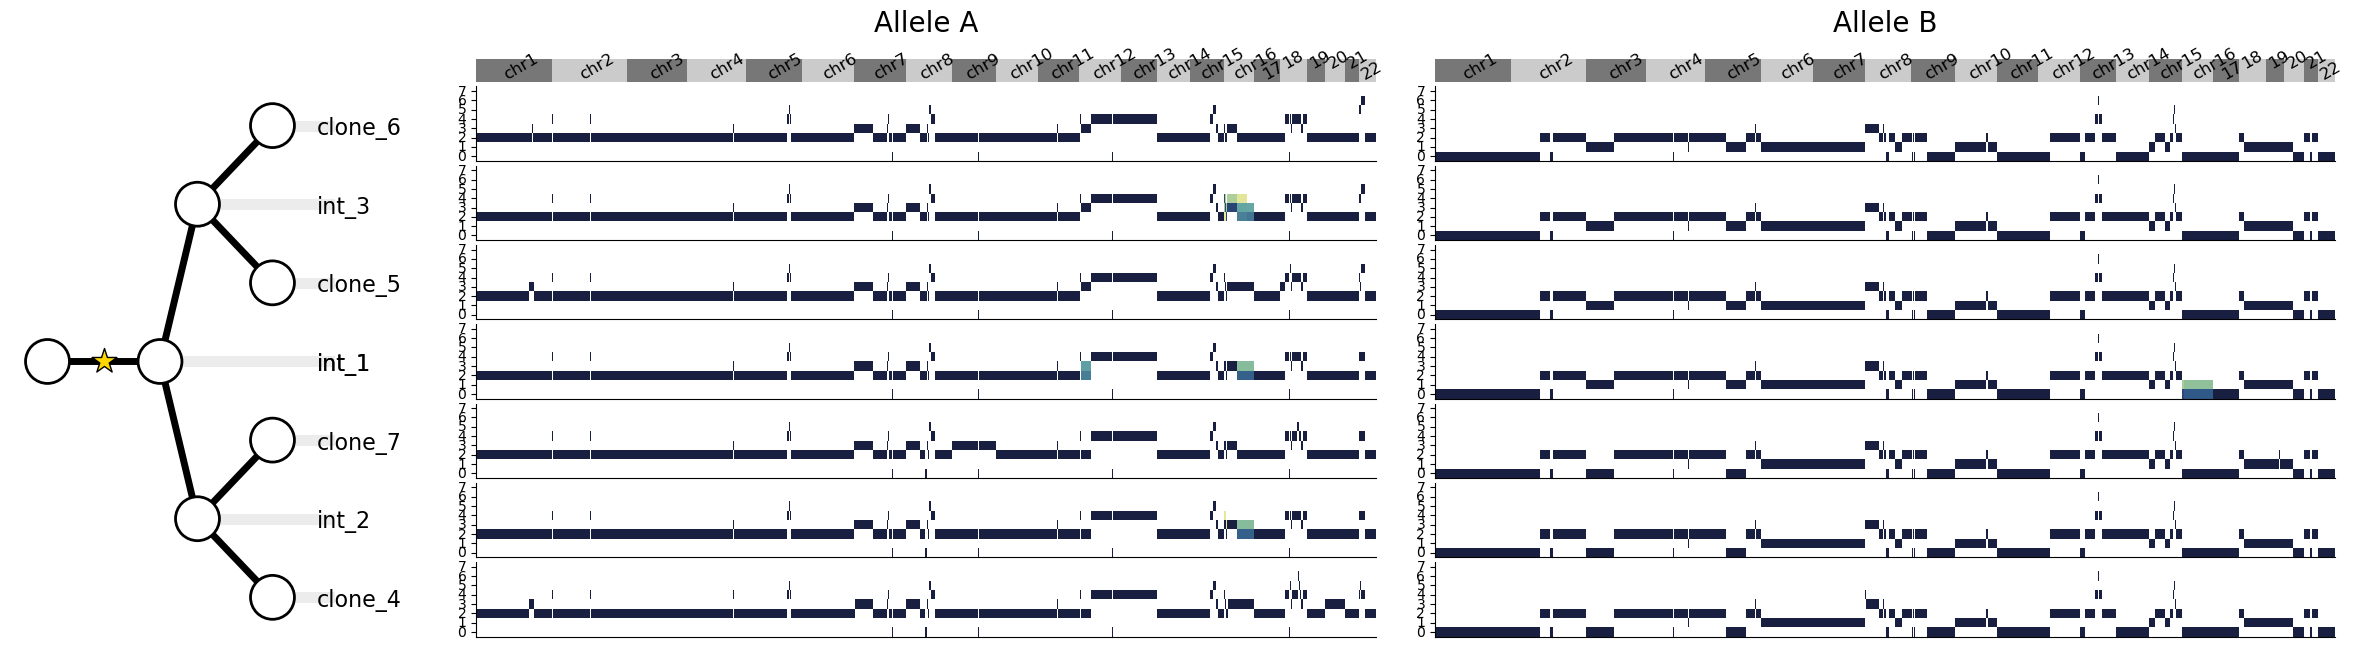

In [15]:
tree_prob_plot.plot_cn_probabilities(spice_res['total_edges_multisol'], spice_res['total_nodes_multisol'], spice_res['chosen_topology_cn_probabilities'], 
                      leaf_order=None, color_mapping={}, ax=None, chrs='all', real_chr_lengths=True, plot_node_names=True, scaley=1, scalex=1)

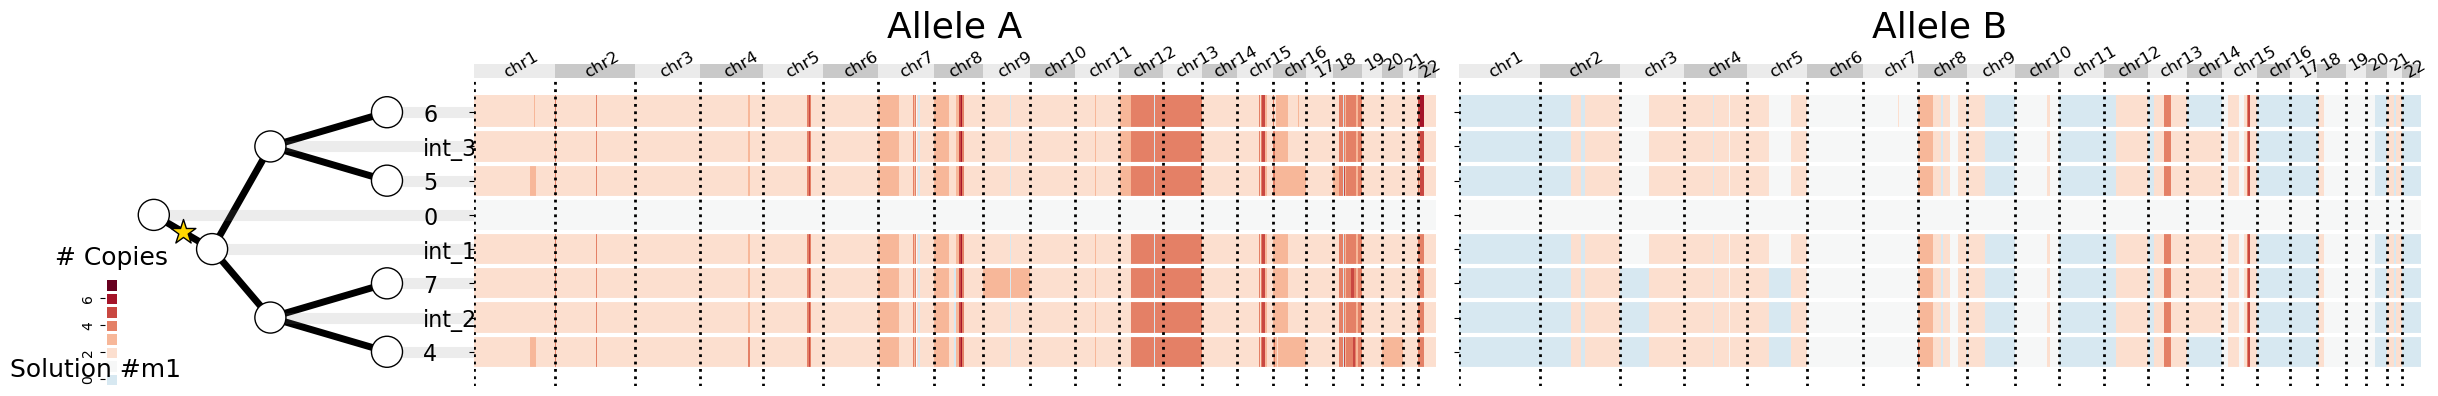

In [17]:
tree_plot.plot_cn_figure(spice_res['total_edges_multisol'], spice_res['total_nodes_multisol'], '0', leaf_order=None, cn_palette='RdBu_r', color_mapping={}, ax=None, plot_root=True, idx='m1', chrs='all', real_chr_lengths=True)